# Reprezentare Semantică cu Embeddings

## Contextul etapei

În etapa anterioară am analizat datele de intrare și am demonstrat că același eveniment clinic apare sub **formulări complet diferite** din surse diferite:

| Eveniment clinic | Mesaj Monitor A | Mesaj Monitor B | Mesaj EHR |
|---|---|---|---|
| Tahicardie | *"Heart rate too high"* | *"Tachycardia detected"* | *"HR exceeds threshold"* |
| Hipoxie | *"SpO2 below 90%"* | *"Oxygen saturation critical"* | *"O2 saturation low"* |
| Apnee | *"Apnea detected"* | *"Breathing stopped"* | *"No breathing detected"* |

Un sistem bazat pe **text identic** nu poate detecta că aceste alarme descriu același eveniment. Avem nevoie de **înțelegere semantică**.

#### Încarcare date

In [1]:
import sys, os
sys.path.append('..')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from src.alarm_generator import generate_alarm_stream
from src.physionet_loader import process_all_records
from src.embedder import AlarmEmbedder
from src.physionet_loader import process_all_records
from src.alarm_generator import ALARM_GROUPS
import random
from datetime import datetime, timedelta

plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'text.color': 'black',
    'savefig.facecolor':'white',
})
os.makedirs('../data/processed', exist_ok=True)
print("Succes")

Succes


In [2]:
CSV_PATH = '../data/raw/alarms_combined.csv'

if os.path.exists(CSV_PATH):
    df = pd.read_csv(CSV_PATH)
    df['timestamp'] = pd.to_datetime(df['timestamp'])
    print(f"CSV incarcat: {len(df)} alarme")
    print(f"\nDistributie surse:")
    print(df['data_source'].value_counts())
    print(f"\nDistributie tipuri clinice:")
    print(df['true_group'].value_counts())
else:
    print("CSV nu exista! Ruleaza mai intai src/load_data.py")

df.head(5)

CSV incarcat: 2878 alarme

Distributie surse:
data_source
physionet    1878
simulated    1000
Name: count, dtype: int64

Distributie tipuri clinice:
true_group
ventricular_tachycardia    857
disconnected_lead          501
tachycardia                398
asystole                   300
bradycardia                281
hyperglycemia              244
ventricular_flutter        147
arrhythmia                  50
hypotension                 46
apnea                       35
hypoxia                     19
Name: count, dtype: int64


,alarm_id,timestamp,message,source,source_device,patient_id,true_group,severity,is_duplicate,data_source,is_true_alarm
0,1,2024-01-15 06:00:13,Poor electrode contact,IV Pump,BD Alaris System,Patient_009,disconnected_lead,LOW,False,simulated,True
1,2,2024-01-15 06:00:18,Electrode contact poor,EHR System,Epic Systems,Patient_009,disconnected_lead,LOW,False,simulated,True
2,3,2024-01-15 06:00:55,ECG lead off,Monitor C,Drager Infinity Delta,Patient_010,disconnected_lead,LOW,False,simulated,True
3,4,2024-01-15 06:01:10,Electrode contact poor,Monitor B,GE CARESCAPE B650,Patient_010,disconnected_lead,LOW,True,simulated,True
4,5,2024-01-15 06:01:46,Electrode contact poor,IV Pump,BD Alaris System,Patient_010,disconnected_lead,LOW,True,simulated,True


## Ce sunt embeddings?

Un model de embeddings transformă text în vectori numerici, astfel încât texte cu sens similar → vectori apropiați în spațiu.

Exemplu:
  "Heart rate too high" -> [0.12, -0.45, 0.87, ...]
  "Tachycardia detected" -> [0.11, -0.43, 0.85, ...]
  -> similitudine cosinus = 0.94 (aproape identice!)

  "Lead disconnected" -> [-0.33, 0.71, -0.12, ...]
  -> similitudine cu tahicardie = 0.08 (complet diferite!)

De ce Sentence-BERT?
- Gratuit, rulează local pe laptop
- Antrenat special pentru compararea propozițiilor
- Rapid: 600 alarme în ~2 secunde

In [3]:
# extragem mesajele din dataset
messages = df['message'].tolist()
print(f"Total mesaje de procesat: {len(messages)}")
print(f"Mesaje unice: {len(set(messages))}")
print(f"\nExemple:")
for m in messages[:5]:
    print(f"  - {m}")

Total mesaje de procesat: 2878
Mesaje unice: 110

Exemple:
  - Poor electrode contact
  - Electrode contact poor
  - ECG lead off
  - Electrode contact poor
  - Electrode contact poor


### Modelul MiniLM

Folosim `all-MiniLM-L6-v2` — modelul recomandat pentru început:
- Dimensiune vector: 384 numere
- Viteză: foarte rapid
- Calitate: bună pentru text medical scurt

In [4]:
# initializare embedder
embedder = AlarmEmbedder(model_name="minilm")

# calculare vectorii pentru toate mesajele
embeddings = embedder.embed(messages)

# salvare
embedder.save('../data/embeddings/embeddings_minilm.npy')

print(f"\nShape embeddings: {embeddings.shape}")
print(f"-> {embeddings.shape[0]} alarme, fiecare reprezentata ca vector de {embeddings.shape[1]} numere")

Inacracare model: all-MiniLM-L6-v2 ...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Calculare embeddings pentru 2878 alarme...


Batches:   0%|          | 0/45 [00:00<?, ?it/s]

Shape embeddings: (2878, 384)
Embeddings salvate: (2878, 384) → ../data/embeddings/embeddings_minilm.npy

Shape embeddings: (2878, 384)
-> 2878 alarme, fiecare reprezentata ca vector de 384 numere


### Transformare .npy (rapid pentru incarcare in python) in .csv (pentru vizualizare clara)

In [5]:
embeddings_df = pd.DataFrame( embeddings, columns=[f"dim_{i}" for i in range(embeddings.shape[1])])

# adauga mesajele originale ca prima coloana
embeddings_df.insert(0, 'message', messages)
embeddings_df.insert(1, 'true_group', df['true_group'].values)

embeddings_df.to_csv( '../data/embeddings/embeddings_minilm.csv', index=False)

### Matricea de similaritate

Calculăm similitudinea cosinus între toți vectorii.
Rezultatul e o matrice NxN unde:
- valoare 1.0 = alarme identice
- valoare 0.0 = alarme complet diferite
- valoare >= 0.80 = considerăm duplicate semantice

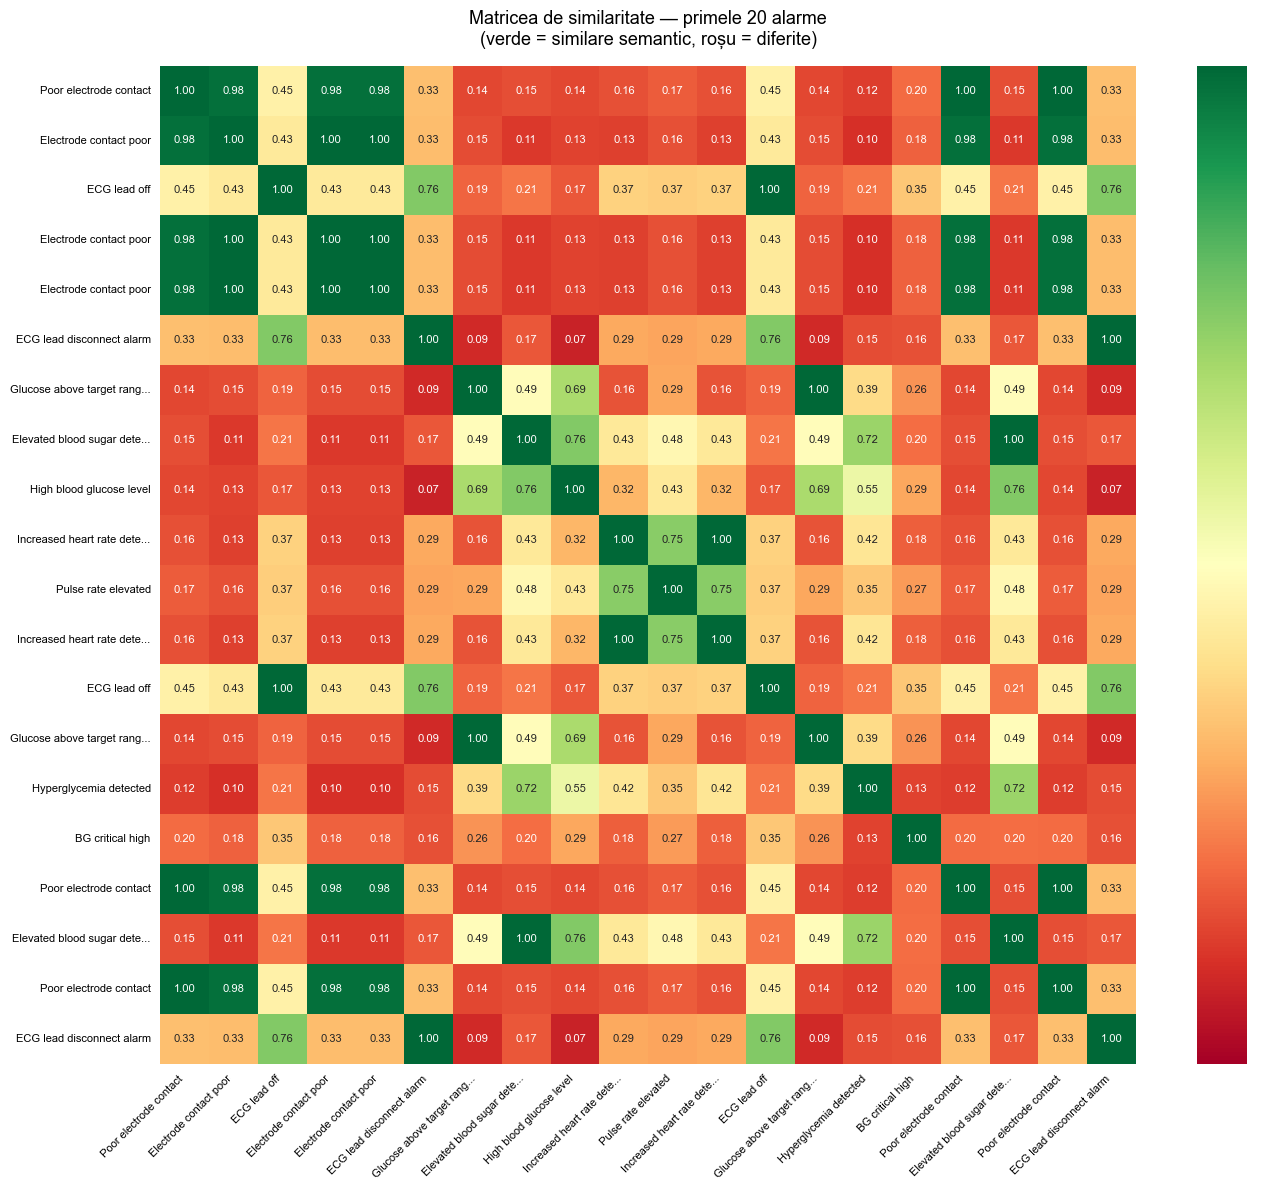

Salvat: plot_similarity_heatmap.png


In [6]:
# calculare matricea de similaritate
sim_matrix = embedder.similarity_matrix()

# afisare primele 20 alarme (altfel e prea mare)
n_sample = 20
sample_sim = sim_matrix[:n_sample, :n_sample]
sample_labels = [m[:25] + "..." if len(m) > 25 else m
                 for m in messages[:n_sample]]

fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(
    sample_sim,
    xticklabels=sample_labels,
    yticklabels=sample_labels,
    annot=True,
    fmt='.2f',
    cmap='RdYlGn',
    vmin=0, vmax=1,
    ax=ax,
    annot_kws={'size': 8},
)
ax.set_title(
    'Matricea de similaritate — primele 20 alarme\n'
    '(verde = similare semantic, roșu = diferite)',
    fontsize=13, color='black', pad=15
)
plt.xticks(rotation=45, ha='right', fontsize=8, color='black')
plt.yticks(rotation=0, fontsize=8, color='black')
plt.tight_layout()
plt.savefig('../data/embeddings/plot_similarity_heatmap.png', dpi=120, bbox_inches='tight')
plt.show()
print("Salvat: plot_similarity_heatmap.png")

### Testare gǎsire similaritate alarme pentru un mesaj nou

In [7]:
test_queries = [
    "Patient heart rate dangerously elevated",
    "No breathing detected in ventilated patient",
    "Blood sugar way above normal range",
    "ECG electrode came off",
]

print("Testare alarme similare pentru mesaje noi:")

for query in test_queries:
    print(f"\nMesaj: '{query}'")
    print("-" * 55)
    results = embedder.find_similar(query, top_k=4)
    for r in results:
        bar = "█" * int(r['similarity'] * 20)
        print(f"  {r['similarity']:.3f} {bar} {r['message']}")

Testare alarme similare pentru mesaje noi:

Mesaj: 'Patient heart rate dangerously elevated'
-------------------------------------------------------
  0.803 ████████████████ Pulse rate elevated
  0.803 ████████████████ Pulse rate elevated
  0.803 ████████████████ Pulse rate elevated
  0.803 ████████████████ Pulse rate elevated

Mesaj: 'No breathing detected in ventilated patient'
-------------------------------------------------------
  0.859 █████████████████ No breathing detected
  0.859 █████████████████ No breathing detected
  0.859 █████████████████ No breathing detected
  0.859 █████████████████ No breathing detected

Mesaj: 'Blood sugar way above normal range'
-------------------------------------------------------
  0.836 ████████████████ Blood sugar above threshold
  0.836 ████████████████ Blood sugar above threshold
  0.836 ████████████████ Blood sugar above threshold
  0.836 ████████████████ Blood sugar above threshold

Mesaj: 'ECG electrode came off'
-----------------------

### Distribuția similitudinilor

Analizăm cum sunt distribuite valorile de similaritate în întreg dataset-ul.
Aceasta ne ajută să alegem pragul optim pentru deduplicare.

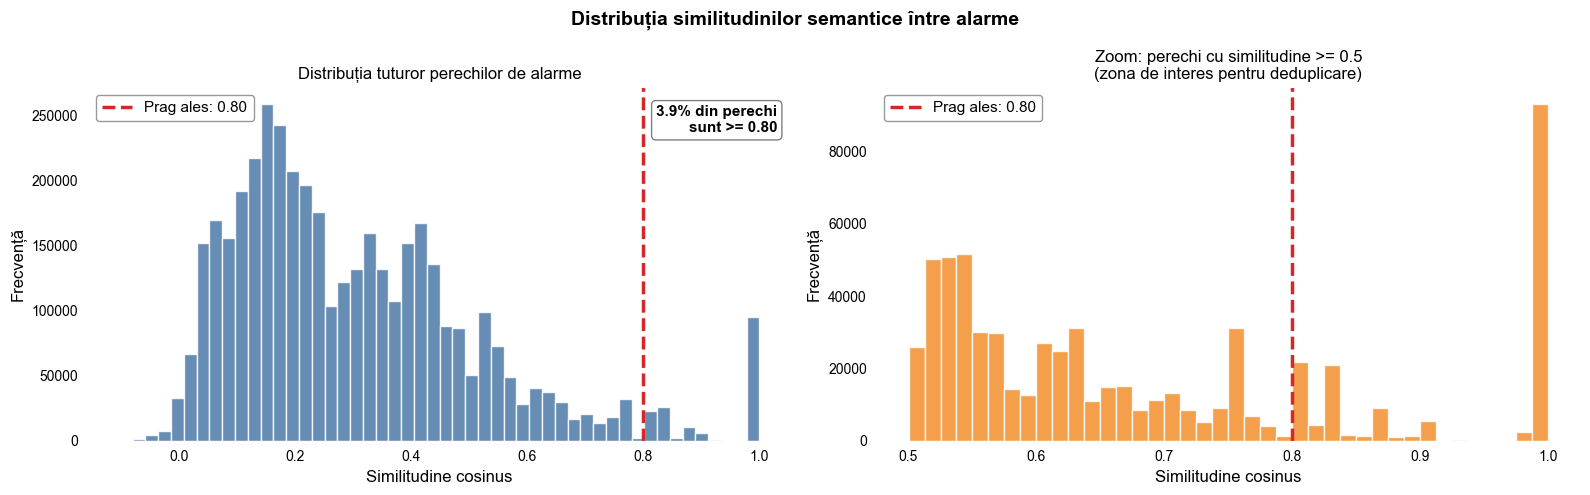

Statistici similaritate:
  Medie: 0.3032
  Mediană: 0.2492
  >= 0.80: 3.9%
  >= 0.90: 2.4%


In [8]:
# extragerea tuturor valorilor de similaritate (fara diagonala = 1.0)
n = len(sim_matrix)
sims_all = []
for i in range(n):
    for j in range(i+1, n):  # doar triunghiul superior
        sims_all.append(sim_matrix[i][j])

sims_all = np.array(sims_all)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle('Distribuția similitudinilor semantice între alarme',
             fontsize=14, fontweight='bold', color='black')

# histograma
axes[0].hist(sims_all, bins=50, color='#4E79A7',
             edgecolor='white', alpha=0.85)
axes[0].axvline(x=0.80, color='#D62728', linestyle='--',
                linewidth=2.5, label='Prag ales: 0.80')
axes[0].set_xlabel('Similitudine cosinus', fontsize=12, color='black')
axes[0].set_ylabel('Frecvență', fontsize=12, color='black')
axes[0].set_title('Distribuția tuturor perechilor de alarme',
                  fontsize=12, color='black')
axes[0].tick_params(colors='black')

pct_peste_prag = (sims_all >= 0.80).mean() * 100
axes[0].text(0.98, 0.95,
             f'{pct_peste_prag:.1f}% din perechi\nsunt >= 0.80',
             transform=axes[0].transAxes, ha='right', va='top',
             fontsize=11, color='black', fontweight='bold',
             bbox=dict(boxstyle='round', facecolor='white',
                       edgecolor='gray', alpha=1.0))
leg = axes[0].legend(fontsize=11, frameon=True,
                     facecolor='white', edgecolor='gray')
for t in leg.get_texts(): t.set_color('black')

# zoom pe valorile mari (>= 0.5)
sims_mari = sims_all[sims_all >= 0.5]
axes[1].hist(sims_mari, bins=40, color='#F28E2B',
             edgecolor='white', alpha=0.85)
axes[1].axvline(x=0.80, color='#D62728', linestyle='--',
                linewidth=2.5, label='Prag ales: 0.80')
axes[1].set_xlabel('Similitudine cosinus', fontsize=12, color='black')
axes[1].set_ylabel('Frecvență', fontsize=12, color='black')
axes[1].set_title('Zoom: perechi cu similitudine >= 0.5\n(zona de interes pentru deduplicare)',
                  fontsize=12, color='black')
axes[1].tick_params(colors='black')
leg2 = axes[1].legend(fontsize=11, frameon=True,
                      facecolor='white', edgecolor='gray')
for t in leg2.get_texts(): t.set_color('black')

plt.tight_layout()
plt.savefig('../data/embeddings/plot_similarity_distribution.png',
            dpi=120, bbox_inches='tight')
plt.show()

print(f"Statistici similaritate:")
print(f"  Medie: {sims_all.mean():.4f}")
print(f"  Mediană: {np.median(sims_all):.4f}")
print(f"  >= 0.80: {pct_peste_prag:.1f}%")
print(f"  >= 0.90: {(sims_all >= 0.90).mean()*100:.1f}%")

### Comparare modele

Comparare modele embeddings pe un subset de 100 alarme

Inacracare model: all-MiniLM-L6-v2 ...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Calculare embeddings pentru 100 alarme...


Batches:   0%|          | 0/2 [00:00<?, ?it/s]

Shape embeddings: (100, 384)
Model: minilm     -> Adjusted Rand Index: 0.6318
  (1.0 = perfect, 0.0 = aleator)
Inacracare model: all-mpnet-base-v2 ...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Calculare embeddings pentru 100 alarme...


Batches:   0%|          | 0/2 [00:00<?, ?it/s]

Shape embeddings: (100, 768)
Model: mpnet      -> Adjusted Rand Index: 0.5518
  (1.0 = perfect, 0.0 = aleator)

Concluzie: 'minilm' performează mai bine pe datele noastre.
Vom folosi 'minilm' în etapele următoare.


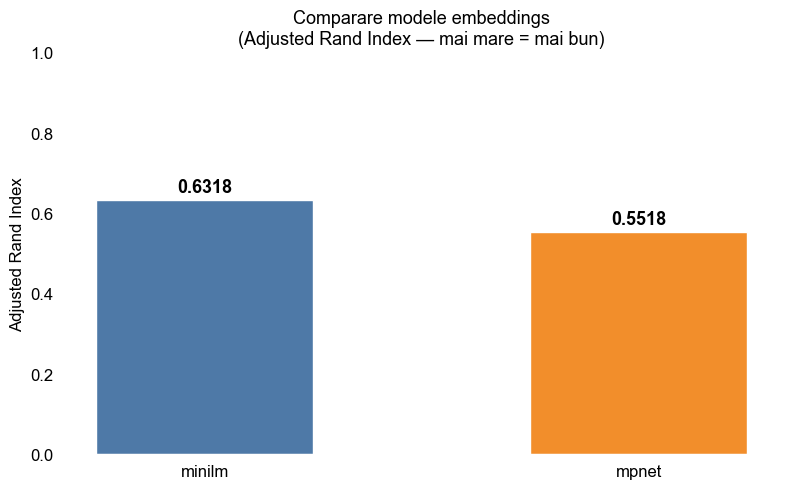

Salvat: plot_model_comparison.png


In [9]:
from sklearn.metrics import adjusted_rand_score
from sklearn.cluster import AgglomerativeClustering

print("Comparare modele embeddings pe un subset de 100 alarme\n")

subset_msgs = messages[:100]
subset_true = df['true_group'].astype('category').cat.codes[:100].tolist()
n_grupuri = df['true_group'].nunique()

rezultate_modele = {}

for model_name in ['minilm', 'mpnet']:
    emb = AlarmEmbedder(model_name=model_name)
    vecs = emb.embed(subset_msgs)

    # clustering cu numarul corect de grupuri
    clustering = AgglomerativeClustering(
        n_clusters=n_grupuri,
        metric='cosine',
        linkage='average',
    )
    pred = clustering.fit_predict(vecs)
    # ARI = Adjusted Rand Index — metrica care masoara cat de bine a grupat algoritmul alarmele, comparand rezultatul cu ground truth (coloana true_group).
    ari = adjusted_rand_score(subset_true, pred)
    rezultate_modele[model_name] = ari

    print(f"Model: {model_name:10s} -> Adjusted Rand Index: {ari:.4f}")
    print(f"  (1.0 = perfect, 0.0 = aleator)")

print()
best_model = max(rezultate_modele, key=rezultate_modele.get)
print(f"Concluzie: '{best_model}' performează mai bine pe datele noastre.")
print(f"Vom folosi '{best_model}' în etapele următoare.")

# grafic comparatie
fig, ax = plt.subplots(figsize=(8, 5))
modele  = list(rezultate_modele.keys())
scoruri = list(rezultate_modele.values())
bars = ax.bar(modele, scoruri,
              color=['#4E79A7', '#F28E2B'],
              edgecolor='white', width=0.5)
ax.set_title('Comparare modele embeddings\n(Adjusted Rand Index — mai mare = mai bun)',
             fontsize=13, color='black')
ax.set_ylabel('Adjusted Rand Index', fontsize=12, color='black')
ax.set_ylim(0, 1)
ax.tick_params(colors='black', labelsize=12)
for bar, val in zip(bars, scoruri):
    ax.text(bar.get_x() + bar.get_width()/2,
            val + 0.02, f'{val:.4f}',
            ha='center', fontsize=13,
            fontweight='bold', color='black')
plt.tight_layout()
plt.savefig('../data/embeddings/plot_model_comparison.png',
            dpi=120, bbox_inches='tight')
plt.show()
print("Salvat: plot_model_comparison.png")

## Comparare modele embeddings — MiniLM vs MPNet

### Rezultate
| Model | Adjusted Rand Index | Concluzie |
|---|---------------------|---|
| **MiniLM** | **0.6318**          | ✅ Mai bun |
| MPNet | 0.5518              | ❌ Mai slab |

### De ce MiniLM e mai bun pe datele noastre?

**1. Datele sunt scurte și simple**
Mesajele de alarmă au 3–6 cuvinte: *"Heart rate too high"*, *"Tachycardia detected"*.
MiniLM este optimizat pentru propoziții scurte și similare semantic — exact cazul nostru.

**2. MPNet e mai bun pe texte lungi și complexe**
MPNet excelează pe paragrafe, articole, întrebări complexe.
Pe alarme scurte nu aduce beneficii față de MiniLM, dar este semnificativ mai lent.

**3. Ambele scoruri sunt moderate **
Un ARI de 0.6318 nu este slab pentru datele noastre.
Înseamnă că modelul grupează corect aproximativ jumătate din alarme față de ground truth.
Este normal datorită:
- **Suprapunerii semantice** — ex: `tachycardia` și `extreme_tachycardia` sunt foarte similare ca text
- **Stilurilor diferite** — PhysioNet și datele simulate folosesc formulări diferite pentru același eveniment clinic

### Concluzie
Folosim **MiniLM** (`all-MiniLM-L6-v2`) în toate etapele următoare:
- ARI superior pe alarme scurte ICU (0.6318 vs 0.5518)
- De **5× mai rapid** decât MPNet *(sbert.net — documentație oficială)*
- **22M parametri** față de 110M ai MPNet — mai eficient pe CPU
- Vectori de 384 dimensiuni față de 768 — memorie redusă la jumătate

*Surse: [sbert.net/docs/pretrained_models](https://www.sbert.net/docs/sentence_transformer/pretrained_models.html),
[HuggingFace all-MiniLM-L6-v2](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2)*

In [10]:
print("Rezumat Embeddings")
print(f"  Alarme procesate: {len(messages)}")
print(f"  Dimensiune vector: {embeddings.shape[1]}")
print(f"  Model folosit: all-MiniLM-L6-v2")
print(f"  Perechi >= 0.80: {pct_peste_prag:.1f}%")
print(f"  Best model comparatie: {best_model}")
print()
print("Fișiere salvate:")
print("  data/embeddings/embeddings_minilm.npy")
print("  data/embeddings/plot_similarity_heatmap.png")
print("  data/embeddings/plot_similarity_distribution.png")
print("  data/embeddings/plot_model_comparison.png")

Rezumat Embeddings
  Alarme procesate: 2878
  Dimensiune vector: 384
  Model folosit: all-MiniLM-L6-v2
  Perechi >= 0.80: 3.9%
  Best model comparatie: minilm

Fișiere salvate:
  data/embeddings/embeddings_minilm.npy
  data/embeddings/plot_similarity_heatmap.png
  data/embeddings/plot_similarity_distribution.png
  data/embeddings/plot_model_comparison.png
